# Project 3: Answering Questions (Phase III) | DATA 601

# Heart Disease Dataset

### Group members

Bhavya Dadhich

Patrick Amoni

Krena Dungrani

---

### Problem statement

Cardiovascular disease is one of the leading causes of death around the world. Procedures such as
angiography can be expensive and invasive. A clinical approach that uses inexpensive, routinely collected
health measures to identify patients at higher risk could therefore help healthcare providers to prioritize
those individuals for further diagnostic testing.

Our question for this project is;

Can routinely available patient characteristics predict heart-disease status well enough to be useful as an
early screening tool and which measurements carry that signal?

Stakeholder: A primary care clinic choosing which patients to refer for more cardiac testing.

Project 1 explored this data and Project 2 built the predictive models. This notebook brings the whole
workflow into one place: it states the question and the desired outcome, describes the data and what limits
our confidence in it, documents every preprocessing step so a teammate can reproduce the work, builds and
tests the models, interprets what they show, and answers the question we started with.


### What changed since Project 2

Two pieces of feedback are addressed in this notebook. All preprocessing that learns something from the
data (imputation and scaling) is now fitted inside a pipeline on the training fold only, and
cross-validation runs on the training set alone so the held-out patients stay untouched until the final
evaluation. Both changes are explained where they occur, in section 3 and section 4.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
BLUE, RUST, GREY, INK = '#1F6FB2', '#C2410C', '#8A9099', '#16233A'
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#C9CDD2', 'grid.color': '#E8EAED'})

---
## 1. Ask a question

### Q1. State question clearly and desired outcome

Restating the question from the problem statement above, so this section stands on its own:

> **Can routinely available patient characteristics predict heart-disease status well enough to be useful
> as an early screening tool and which measurements carry that signal?**

**Stakeholder:** a primary care clinic choosing which patients to refer for more cardiac testing. The
clinic has to make that referral decision *before* an angiogram result exists, which is what makes the
question worth asking.

**Our ideal outcome, stated before we modelled.** Two things:

1. A model that beats the majority-class baseline by a wide margin, using only measurements a clinic can
   obtain without a catheter or a nuclear scan.
2. A ranked account of which measurements carry the signal, with the direction of each effect, so the
   result can be explained to a clinician rather than just reported as a number.

We treat the project as a success if the cheap-measurement model keeps most of the predictive signal of the
full model. We return to this test explicitly in section 6.

### Q2. Describe dataset(s), discuss accuracy/reliability/validity/sample selection


**Source.** The Cleveland subset of the UCI Heart Disease dataset, taken from the course `dataFDS` folder
as `heart.csv`. It holds 303 patient records with 13 clinical measurements and one binary outcome column
(`target`). The measurements are a mix of patient history (age, sex, chest pain type), routine clinical
readings (resting blood pressure, cholesterol, fasting blood sugar, resting ECG), exercise stress test
results (maximum heart rate, exercise-induced angina, ST depression, ST slope) and two results that require
an invasive or nuclear procedure (`ca`, the number of major vessels coloured by fluoroscopy, and `thal`,
a thallium stress scan).

**Sample selection is the quality issue that matters most here.** These are not patients drawn from a
general population. They were already referred to a cardiology service and worked up for angiography, so
the sample is enriched for people a doctor already suspected of having heart disease. That has a direct
consequence for our question: a screening model trained on this sample is being asked to separate patients
who are all, in some sense, already suspicious. Performance on a true primary-care population, where the
base rate of disease is far lower, would almost certainly be worse. Any number in this notebook should be
read as an upper bound.

Three further constraints that bound what we can claim. The data was collected at one clinic in 1988, so it
predates modern treatment. The sample is mostly male. And the file carries nothing on smoking, diet, family
history or medication, which a cardiologist would want.


### Q3. What kind of machine learning problem this is

**Supervised learning.** Every row carries a known outcome label, so the model learns a mapping from
measurements to a label that we can check against ground truth. This is not a clustering or
dimension-reduction problem, where no label exists.

**Binary classification.** The outcome takes one of two values. It is not regression, which would predict a
continuous quantity. The correct evaluation tools are therefore accuracy, a confusion matrix and per-class
recall, not an error measure like RMSE.

**Which models and why.** We fit three, deliberately chosen at increasing levels of flexibility, because
comparing them is what reveals overfitting. A single model cannot tell you that.

| Model | Flexibility | Why we included it |
|---|---|---|
| Logistic regression | Low. One weight per feature, one linear boundary | It is the only one of the three that gives signed coefficients, which Q5 needs |
| Decision tree, depth 4 | Medium. Can stack conditions, capped at 4 levels | Readable as rules, and the depth cap is an explicit brake on memorising |
| Random forest, 200 trees | High. 200 unrestricted trees averaged | Usually the strongest, but a black box |

Our question has two halves. "Can we predict" needs accuracy. "Which measurements carry the signal" needs
interpretability. That is why an interpretable model is in the set rather than only the strongest one.

## 2. Data understanding, exploration, and visualization

We load the file, confirm its shape and check what the outcome column looks like before anything else.
The class balance matters because it sets the score that any useful model has to beat.

In [2]:
# Load the data.
import os
CANDIDATES = ["data/heart.csv", "../data/heart.csv",
              "heart.csv", "heart_data.csv"]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(
        "No CSV found. Run from the repository root, where it sits at data/heart.csv, or upload it to the Colab session. "
        f"Looked in: {CANDIDATES}")

heart_raw = pd.read_csv(path)
print("Loaded:", path, " shape as read:", heart_raw.shape)

heart_dedup = heart_raw.drop_duplicates().reset_index(drop=True)
print("After removing the duplicate row:", heart_dedup.shape)
heart_dedup.head()

Loaded: heart_data.csv  shape as read: (303, 14)
After removing the duplicate row: (302, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [3]:
# Descriptive statistics for the five continuous variables.
continuous = ["age", "trestbps", "chol", "thalach", "oldpeak"]
summary = heart_dedup[continuous].describe().T[["mean", "50%", "std", "min", "max"]]
summary.columns = ["mean", "median", "std", "min", "max"]
summary["skew"] = heart_dedup[continuous].skew()
summary.round(2)

,mean,median,std,min,max,skew
age,54.42,55.5,9.05,29.0,77.0,-0.20
trestbps,131.60,130.0,17.56,94.0,200.0,0.72
chol,246.50,240.5,51.75,126.0,564.0,1.15
thalach,149.57,152.5,22.90,71.0,202.0,-0.53
oldpeak,1.04,0.8,1.16,0.0,6.2,1.27


**Why the reader needs this.** Two things matter for later sections. `chol` and `oldpeak` are clearly
right-skewed, with the mean well above the median, which is why section 3 imputes with a median rather than
a mean. And the five variables are on wildly different scales: cholesterol runs into the hundreds while ST
depression runs from 0 to about 6. That is the reason the coefficients in section 5 have to be standardised
before they can be compared.

In [4]:
# Who is in this sample.
print("Sex (1 = male):")
print((heart_dedup["sex"].value_counts(normalize=True) * 100).round(1).to_string())
print(f"\nMale patients: {(heart_dedup['sex'] == 1).sum()} of {len(heart_dedup)}")

Sex (1 = male):
sex
1    68.2
0    31.8

Male patients: 206 of 302


This is a **mostly male sample**, roughly 68 percent. It is one of the limitations recorded in section 6:
nothing here establishes that the model would behave the same way for women.

In [5]:
# The outcome column, and the score a model must beat.
# One exact duplicate row is removed first (the full data-quality check is in
# section 3). The baseline must be computed on the same 302 patients the models
# are trained on, otherwise it does not describe the score they have to beat.
counts = heart_dedup["target"].value_counts()
baseline = counts.max() / len(heart_dedup)

print("Outcome counts:")
print(counts.to_string())
print(f"\nMajority-class baseline: {baseline:.3f}")
print("A model that ignored every measurement and always guessed the larger group")
print(f"would score {baseline:.1%}. That is the floor, not zero.")

Outcome counts:
target
1    164
0    138

Majority-class baseline: 0.543
A model that ignored every measurement and always guessed the larger group
would score 54.3%. That is the floor, not zero.


**Why the reader needs this.** Accuracy means nothing without the baseline. At roughly 54 percent, a model
scoring 0.60 would be nearly worthless while one scoring 0.85 is doing real work. Every accuracy figure in
this notebook should be read against that floor.

### 2.1 Which measurements relate to the outcome

Before choosing a model we want to know what each measurement is worth on its own. The chart below ranks
all 13 variables by the **strength** of their correlation with the outcome, with colour carrying the sign.

We rank by absolute value on purpose. Because the direction of the outcome label is contested (Q2), every
sign on this chart would flip if the labels were reversed, while the magnitudes would not move. Ranking by
strength gives a reading that holds either way.

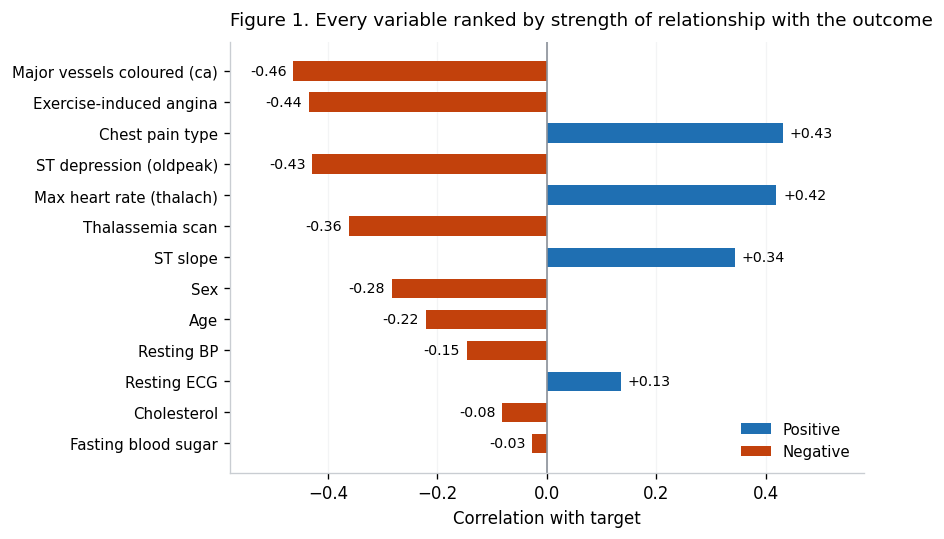

In [6]:
# Correlation of every variable with the outcome, ranked by strength.
# ca = 4 and thal = 0 are outside their documented ranges (see section 3); for this
# exploratory chart only, they are filled so the correlation can be computed.
expl = heart_raw.drop_duplicates().reset_index(drop=True).copy()
expl.loc[expl["ca"] == 4, "ca"] = np.nan
expl.loc[expl["thal"] == 0, "thal"] = np.nan
expl["ca"] = expl["ca"].fillna(expl["ca"].median())
expl["thal"] = expl["thal"].fillna(expl["thal"].mode()[0])

corr = expl.corr(numeric_only=True)["target"].drop("target")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)

LABELS = {"ca": "Major vessels coloured (ca)", "exang": "Exercise-induced angina",
          "cp": "Chest pain type", "oldpeak": "ST depression (oldpeak)",
          "thalach": "Max heart rate (thalach)", "thal": "Thalassemia scan",
          "slope": "ST slope", "sex": "Sex", "age": "Age",
          "restecg": "Resting ECG", "trestbps": "Resting BP",
          "chol": "Cholesterol", "fbs": "Fasting blood sugar"}

fig, ax = plt.subplots(figsize=(7.4, 4.6))
ypos = np.arange(len(corr))[::-1]
ax.barh(ypos, corr.values, height=0.62,
        color=[RUST if v < 0 else BLUE for v in corr.values])
ax.set_yticks(ypos); ax.set_yticklabels([LABELS[i] for i in corr.index], fontsize=9)
ax.axvline(0, color=GREY, lw=1)
for yy, v in zip(ypos, corr.values):
    ax.text(v + (0.012 if v > 0 else -0.012), yy, f"{v:+.2f}",
            va="center", ha="left" if v > 0 else "right", fontsize=8.5)
ax.set_xlim(-0.58, 0.58); ax.set_xlabel("Correlation with target")
ax.set_title("Figure 1. Every variable ranked by strength of relationship with the outcome",
             fontsize=11, loc="left", pad=10)
ax.legend(handles=[Patch(facecolor=BLUE, label="Positive"),
                   Patch(facecolor=RUST, label="Negative")],
          loc="lower right", frameon=False, fontsize=9)
ax.grid(axis="x", alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Reading Figure 1.** `ca`, the count of major vessels coloured by fluoroscopy, has the strongest
relationship at **-0.46**, and it is the one measurement that requires a catheter. Exercise-induced angina
follows at **-0.44**. Chest pain type is third at **+0.43**, and that is simply a question you ask the
patient, with ST depression (**-0.43**) and maximum heart rate (**+0.42**) just behind it. Three of those
four cheap measurements come from a single treadmill test.

That pattern is what made our question worth asking. Only 2 of the 13 measurements need an invasive or
nuclear procedure, and the cheap ones sit immediately behind them in strength.

Two cautions. First, cholesterol is near the bottom at **-0.08**, which surprised us; section 5 shows why
that is not the whole story. Second, a Pearson correlation is a proper measure for the binary variables
here and a reasonable summary for ordered counts, but for the three genuinely nominal variables on
this chart, chest pain type, resting ECG and the thallium scan, whose codes are labels rather than amounts,
it is only a rough proxy. We use this chart to decide what
deserves attention, not as evidence. The model coefficients in section 5 are what we actually rely on.

### 2.2 How the two outcome groups differ

The chart below compares the two groups on four measurements, with the gap between group means expressed in
standard deviations so that variables measured in different units can be compared directly.

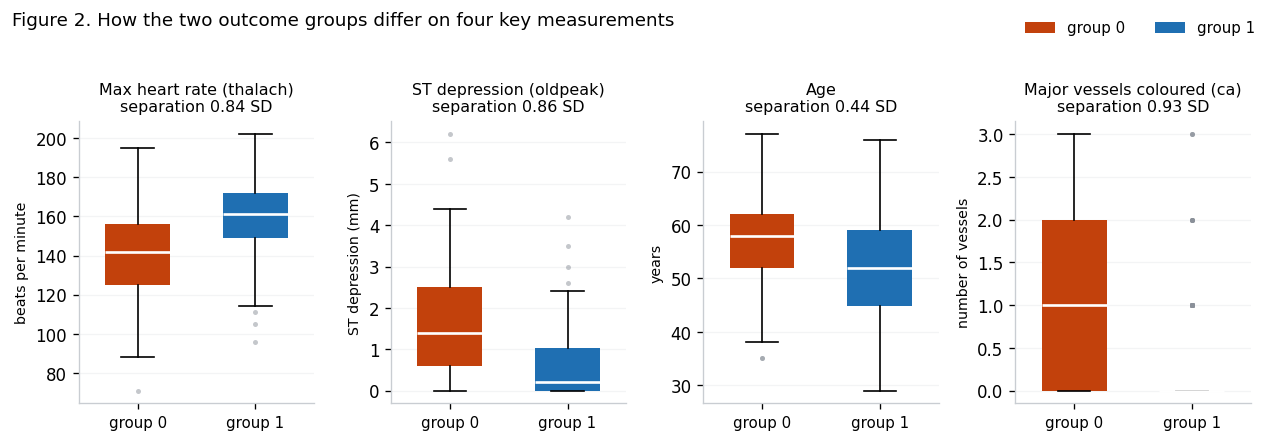

Group means:
          age  thalach  oldpeak    ca
target                               
0       56.60   139.10     1.59  1.14
1       52.59   158.38     0.59  0.27

Exercise-induced angina rate by group:
target
0    0.551
1    0.140


In [7]:
cvars = ["thalach", "oldpeak", "age", "ca"]
UNITS = {"thalach": "beats per minute", "oldpeak": "ST depression (mm)",
         "age": "years", "ca": "number of vessels"}
fig, axes = plt.subplots(1, 4, figsize=(10.6, 3.5))
for ax, c in zip(axes, cvars):
    data = [expl.loc[expl.target == 0, c].values, expl.loc[expl.target == 1, c].values]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55,
                    medianprops=dict(color="white", lw=1.6),
                    flierprops=dict(marker="o", ms=3, mfc=GREY, mec="none", alpha=0.5))
    for patch, col in zip(bp["boxes"], [RUST, BLUE]):
        patch.set_facecolor(col); patch.set_edgecolor("none")
    sep = abs(expl.loc[expl.target == 0, c].mean()
              - expl.loc[expl.target == 1, c].mean()) / expl[c].std()
    ax.set_xticks([1, 2]); ax.set_xticklabels(["group 0", "group 1"], fontsize=9)
    ax.set_ylabel(UNITS[c], fontsize=8.5)
    ax.set_title(f"{LABELS[c]}\nseparation {sep:.2f} SD", fontsize=9.5)
    ax.grid(axis="y", alpha=0.5); ax.set_axisbelow(True)
fig.suptitle("Figure 2. How the two outcome groups differ on four key measurements",
             fontsize=11, x=0.012, ha="left", y=1.04)
fig.legend(handles=[Patch(facecolor=RUST, label="group 0"),
                    Patch(facecolor=BLUE, label="group 1")],
           loc="upper right", bbox_to_anchor=(1, 1.05), ncol=2, frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

print("Group means:")
print(expl.groupby("target")[["age", "thalach", "oldpeak", "ca"]].mean().round(2).to_string())
print("\nExercise-induced angina rate by group:")
print(expl.groupby("target")["exang"].mean().round(3).to_string())

**Reading Figure 2, and the label problem it exposes.** The groups separate cleanly. Affected vessel count gives the
widest gap at 0.93 standard deviations, with ST depression at 0.86 and maximum heart rate at 0.84 just
behind. Those are large differences for clinical data.

The direction is what matters for Q2. **Group 0 is older, reaches a lower peak heart rate, has more ST
depression and has a higher affected-vessel count**, and the printed table shows it also has roughly four
times the rate of exercise-induced angina. On every clinical indicator available, group 0 looks like the
group with disease. That contradicts the published description of this dataset, which says `target = 1`
means disease present.

We have not resolved it, so we do not assert either reading. What we can say is which of our results depend
on it. The accuracies, the overfitting comparison and the screening result in section 6 are all unaffected,
because they are magnitudes. Only the clinical direction of the coefficients in section 5 and the reading
of the confusion matrix in section 4 depend on which group is which, and both are written conditionally.

### 2.3 The strongest single pattern in the data

A raw count plot of `ca` would hide what matters, because a level with few patients produces a short bar
even when its rate is extreme. Converting to the proportion of patients falling in group 0, with a
reference line at the overall rate, shows the pattern directly.

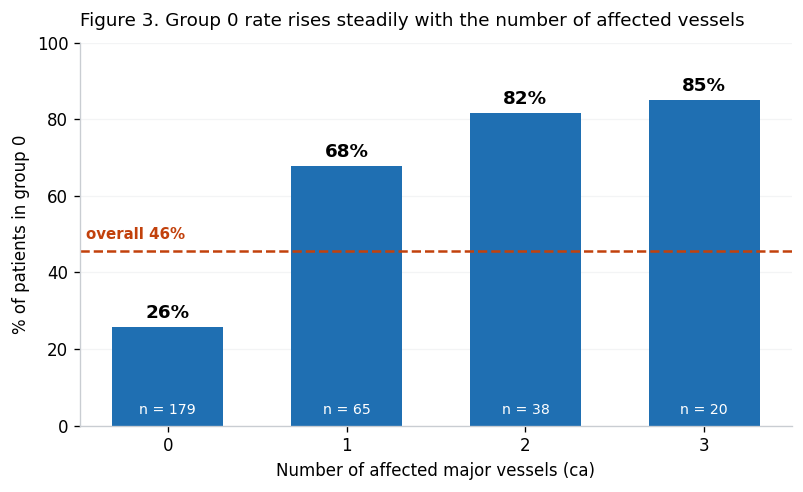

In [8]:
# Group 0 rate by number of affected vessels, against the overall rate.
prop = pd.crosstab(expl["ca"], expl["target"], normalize="index")[0] * 100
overall = (expl["target"] == 0).mean() * 100

fig, ax = plt.subplots(figsize=(6.8, 4.2))
bars = ax.bar(range(len(prop)), prop.values, width=0.62, color=BLUE)
for bar, v in zip(bars, prop.values):
    ax.text(bar.get_x() + bar.get_width()/2, v + 2.5, f"{v:.0f}%",
            ha="center", fontsize=11, fontweight="bold")
counts = expl["ca"].value_counts().sort_index()
for i, n in enumerate(counts.values):
    ax.text(i, 3, f"n = {n}", ha="center", fontsize=8.5, color="white")
ax.axhline(overall, color=RUST, ls="--", lw=1.5)
ax.text(-0.46, overall + 3, f"overall {overall:.0f}%", color=RUST, fontsize=9, fontweight="bold")
ax.set_xticks(range(len(prop)))
ax.set_xticklabels([str(int(i)) for i in prop.index])
ax.set_xlabel("Number of affected major vessels (ca)")
ax.set_ylabel("% of patients in group 0")
ax.set_ylim(0, 100)
ax.set_title("Figure 3. Group 0 rate rises steadily with the number of affected vessels",
             fontsize=11, loc="left", pad=10)
ax.grid(axis="y", alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Reading Figure 3.** The group 0 rate climbs in an orderly staircase as the affected vessel count rises.
This is the strongest single pattern in the dataset and it is exactly the kind of structure a raw count
plot conceals, because the higher vessel counts contain few patients.

It also confirms that `ca` is genuinely **ordinal**: the effect moves steadily in one direction as the
count increases. That is the evidence behind leaving it as a number in section 3 rather than one-hot
encoding it.

## 3. Data wrangling and preprocessing

Every step below is here so a teammate can reproduce our work. We say what we did, why, and what the
alternative would have cost.

### 3.1 What is actually wrong with this data

`isnull().sum()` returns zero, so pandas reports no missing values. That is misleading. Checking each
column against its documented range turns up values that cannot be real measurements.

In [9]:
# Data quality check: duplicates, and values outside their documented ranges.
print("Missing values reported by pandas:", heart_raw.isnull().sum().sum())
print("Duplicate rows:", heart_raw.duplicated().sum())

heart = heart_raw.drop_duplicates().reset_index(drop=True)
print("Rows after removing the duplicate:", len(heart))

print(f"\nca  = 4 (documented range 0-3): {(heart['ca'] == 4).sum()} patients")
print(f"thal = 0 (documented range 1-3): {(heart['thal'] == 0).sum()} patients")

Missing values reported by pandas: 0
Duplicate rows: 1
Rows after removing the duplicate: 302

ca  = 4 (documented range 0-3): 4 patients
thal = 0 (documented range 1-3): 2 patients


**What we did and why.** One exact duplicate row was removed, leaving 302 patients. Keeping it would have
counted one patient twice and let the same record sit in both the training and test sets.

The out-of-range codes are a judgement call and we want to be clear that it is one. `ca` is documented as
0 to 3 and the file contains 4s. `thal` is documented as 1 to 3 and the file contains 0s. These are not
measurements the instruments could produce, so we read them as missing readings that were written into the
file as numbers, and recode them to `NaN`.

We could be wrong. The alternative reading is an undocumented fourth category. We chose the first because
the counts are tiny and because a genuine extra level would be documented somewhere in a dataset this widely
used. The sensitivity check below shows the choice does not move the result either way.

In [10]:
# Recode the out-of-range codes as genuinely missing.
# NOTE: we only mark them here. The imputation itself happens inside the pipeline
# in section 3.3, so that it is fitted on training data only.
heart.loc[heart["ca"] == 4, "ca"] = np.nan
heart.loc[heart["thal"] == 0, "thal"] = np.nan
print("Cells now marked missing:", heart.isnull().sum().sum())
print(heart[["ca", "thal"]].isnull().sum().to_string())

Cells now marked missing: 6
ca      4
thal    2


In [11]:
# Sensitivity check: does imputing rather than dropping change the picture?
imputed = heart.copy()
imputed["ca"] = imputed["ca"].fillna(imputed["ca"].median())
dropped = heart.dropna()

print(f"ca correlation with target, imputing : {imputed['ca'].corr(imputed['target']):.3f}")
print(f"ca correlation with target, dropping : {dropped['ca'].corr(dropped['target']):.3f}")
print(f"\nRows kept by imputing: {len(imputed)}   by dropping: {len(dropped)}")

ca correlation with target, imputing : -0.464
ca correlation with target, dropping : -0.467

Rows kept by imputing: 302   by dropping: 296


The two options differ in the third decimal place. We impute rather than drop because it keeps the sample
size, and with 302 patients we did not want to lose six of them for a difference that small.

**Which imputation, and why not the mean.** `ca` is an ordered count and it is right-skewed, with most
patients at zero. A mean would return something like 0.67 vessels, which is not a value the measurement can
take; the median returns a real one. `thal` is a nominal category, where neither a mean nor a median means
anything, so the only sensible choice is the most frequent category.

### 3.2 How each variable is represented

The variables are all stored as numbers, but a stored type is not a statistical type. Three of them are
**nominal**: the integers are labels, not amounts. Chest pain type 3 is not three times chest pain type 1,
it is a different kind of chest pain.

That distinction decides the encoding:

| Variable | Type | Treatment | Reason |
|---|---|---|---|
| `cp`, `restecg`, `thal` | Nominal | One-hot encoded | The codes are labels. Left as single columns, a linear model would be forced to assume the categories sit at equal intervals on a scale |
| `ca`, `slope` | Ordinal | Left as numbers | The order is real information. 3 affected vessels genuinely is more than 1. One-hot encoding would throw that away and make the model relearn it from 241 rows |
| `age`, `trestbps`, `chol`, `thalach`, `oldpeak` | Continuous | Left as numbers, scaled for logistic regression | Already amounts |
| `sex`, `fbs`, `exang` | Binary | Left as numbers | A 0/1 column needs no encoding |

We use `drop="first"` on the one-hot encoder. Without it, the dummy columns for a variable sum to 1 for
every patient, so they are perfectly redundant and the coefficients become unstable. Dropping one level
makes it the reference category and the remaining coefficients are read relative to it.

### 3.3 The pipeline, and why the order of operations matters

**This is the part we changed after Part 2.** In Part 2 we computed the median and the mode on the full
dataset and filled the missing values before splitting. That leaks information: the fill values were
computed using rows that later became test data, so the test score was flattered.

The fix is to put every step that *learns something from the data* inside a pipeline. A `SimpleImputer`
learns a median. A `StandardScaler` learns a mean and a standard deviation. A `OneHotEncoder` learns the
set of categories. All three must see training data only.

Note also that `thal` has to be imputed **before** it is one-hot encoded. If a `NaN` reaches the encoder it
produces all-zero dummy columns, which silently makes a missing reading look like the reference category.
The `ColumnTransformer` below enforces that order.

In [12]:
# Split the columns by how they must be treated.
NOMINAL = ["cp", "restecg", "thal"]                               # labels -> one-hot
NUMERIC = [c for c in heart.columns if c not in NOMINAL + ["target"]]  # amounts and ordered codes

print("One-hot encoded :", NOMINAL)
print("Left as numbers :", NUMERIC)


def make_preprocessor(scale, numeric=NUMERIC, nominal=NOMINAL):
    """Impute, then scale (optionally), then one-hot encode.
    Every step is fitted on training data only when used inside cross-validation."""
    numeric_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric),
        ("nom", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(drop="first", sparse_output=False,
                                                   handle_unknown="infrequent_if_exist"))]), nominal),
    ])


def make_model(classifier, scale):
    return Pipeline([("prep", make_preprocessor(scale)), ("clf", classifier)])

One-hot encoded : ['cp', 'restecg', 'thal']
Left as numbers : ['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'slope', 'ca']


**Why scaling is applied to logistic regression only.** Logistic regression fits a weighted sum, so the size
of each coefficient depends on the units the variable happens to be measured in. One unit of cholesterol is
1 mg/dl, which is almost nothing; one unit of affected vessels is a whole blocked artery. Standardising puts
every variable on the same ruler, where one unit means one standard deviation, and that is what makes the
coefficients in section 5 comparable to each other.

Tree models are unaffected by scaling. A tree only asks whether a value sits above or below a cut point, and
that answer does not change when the axis is rescaled. We verify this claim empirically in section 4 rather
than asserting it.

### 3.4 Splitting the data

We hold back 20 percent of the patients and do not touch them until the final evaluation in section 4.
`stratify` preserves the class balance in both halves, so a bad random draw cannot hand us a test set with a
different mix from the training set.

In [13]:
# Hold out 20% of patients. These rows are not used again until the final evaluation.
X = heart.drop(columns="target")
y = heart["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print(f"Training set: {len(X_train)} patients")
print(f"Test set:     {len(X_test)} patients")
print("\nClass balance preserved by stratify (%):")
print(pd.DataFrame({
    "train": (y_train.value_counts(normalize=True) * 100).round(1),
    "test":  (y_test.value_counts(normalize=True) * 100).round(1)}).to_string())

Training set: 241 patients
Test set:     61 patients

Class balance preserved by stratify (%):
        train  test
target             
1        54.4  54.1
0        45.6  45.9


---
## 4. Building and testing the model

We fit the three models from Q3 on the training set. Each is wrapped in the pipeline from section 3, so the
imputer, the scaler and the encoder are refitted from scratch on whatever training data they are given.

In [14]:
# Three models at increasing flexibility. Only logistic regression gets the scaler.
models = {
    "Logistic regression":       make_model(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), scale=True),
    "Decision tree (depth 4)":   make_model(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), scale=False),
    "Random forest (200 trees)": make_model(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE), scale=False),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: fitted")

Logistic regression: fitted
Decision tree (depth 4): fitted
Random forest (200 trees): fitted


### 4.1 Cross-validation, on the training set only

A single 61-patient test set is a thin basis for a comparison: one patient is worth 1.6 percentage points.
Cross-validation splits the training data five ways, trains on four parts and tests on the fifth, rotates
through all five and averages. Every training patient is predicted once by a model that did not see them.

**This is the second change since Part 2.** Previously we ran cross-validation on the whole dataset, which
meant the 61 held-out patients were inside the cross-validation training folds. That defeats the purpose of
holding them out. Cross-validation now runs on `X_train` only, and the test set stays sealed.

We also report the standard deviation across the five folds, because the spread is what tells you whether
two models are actually distinguishable.

In [15]:
# Performance table. Cross-validation uses the TRAINING set only.
results = []
for name, model in models.items():
    cv = cross_val_score(model, X_train, y_train, cv=5)
    results.append({
        "model": name,
        "train accuracy": model.score(X_train, y_train),
        "test accuracy":  model.score(X_test, y_test),
        "5-fold CV mean": cv.mean(),
        "CV fold SD":     cv.std(),
    })

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df["train - test gap"] = (results_df["train accuracy"]
                                  - results_df["test accuracy"]).round(3)
results_df

,train accuracy,test accuracy,5-fold CV mean,CV fold SD,train - test gap
model,,,,,
Logistic regression,0.871,0.836,0.847,0.050,0.035
Decision tree (depth 4),0.900,0.721,0.776,0.048,0.179
Random forest (200 trees),1.000,0.754,0.822,0.041,0.246


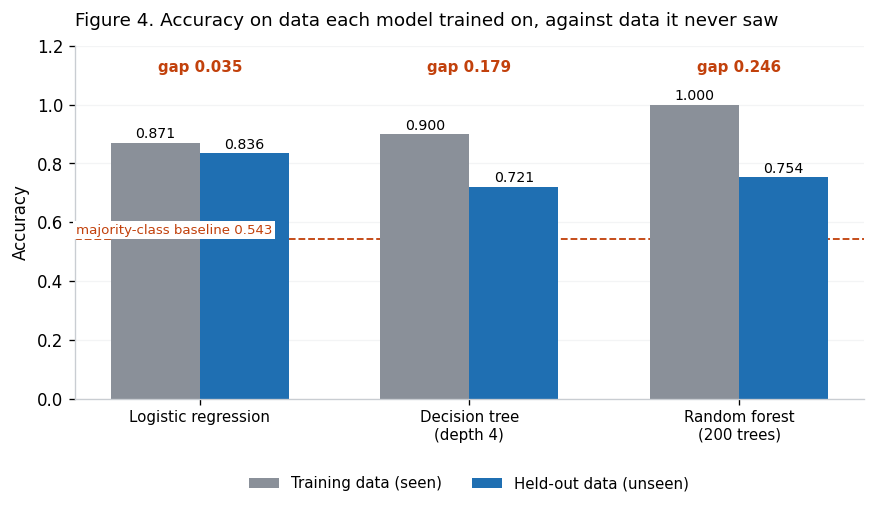

In [16]:
# Figure 4: training accuracy against held-out accuracy, for all three models.
fig, ax = plt.subplots(figsize=(7.4, 4.5))
names = [n.replace(" (", "\n(") for n in results_df.index]
train_acc = results_df["train accuracy"].values
test_acc  = results_df["test accuracy"].values
xpos, width = np.arange(3), 0.33

ax.bar(xpos - width/2, train_acc, width, color=GREY, label="Training data (seen)")
ax.bar(xpos + width/2, test_acc,  width, color=BLUE, label="Held-out data (unseen)")
for i, (a, b) in enumerate(zip(train_acc, test_acc)):
    ax.text(i - width/2, a + 0.015, f"{a:.3f}", ha="center", fontsize=8.5)
    ax.text(i + width/2, b + 0.015, f"{b:.3f}", ha="center", fontsize=8.5)
    ax.text(i, 1.11, f"gap {a-b:.3f}", ha="center", fontsize=9, color=RUST, fontweight="bold")
ax.axhline(baseline, color=RUST, ls="--", lw=1.1, zorder=0)
ax.text(-0.46, baseline + 0.018, f"majority-class baseline {baseline:.3f}",
        fontsize=8, color=RUST, ha="left",
        bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
ax.set_xticks(xpos); ax.set_xticklabels(names, fontsize=9)
ax.set_ylim(0, 1.20); ax.set_ylabel("Accuracy")
ax.set_title("Figure 4. Accuracy on data each model trained on, against data it never saw",
             fontsize=11, loc="left", pad=12)
ax.legend(frameon=False, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.30), ncol=2)
ax.grid(axis="y", alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### Q4. Model performance evaluated and generalization discussed

**The simplest model generalises best.** Read Figure 4 as three pairs rather than six bars. The height of
each pair is how well the model did on data it had already seen; the drop to the second bar is how much of
that was memorising.

The random forest scored a **perfect 1.000** on the training data and **0.754** on patients it had never
seen, a gap of **0.246**. A perfect training score is not itself a finding, because an unrestricted forest
will fit its training set almost exactly by construction. The finding is the gap, and the fact that its
held-out score is the second lowest of the three.

Logistic regression was the **worst at memorising** (0.871) and the **best on new patients** (0.836), a gap
of only **0.035**. With 241 training rows and 17 features after encoding, the flexible models had enough
freedom to fit noise, and did.

**Cross-validation agrees on the ranking**, which tells us this is not an artefact of one lucky split. But
the fold standard deviations are around 0.04 to 0.05, so logistic regression and the random forest overlap
substantially. We would not claim logistic regression is significantly more accurate than the forest. The
claim we will defend is narrower and stronger: **the extra flexibility bought nothing**, and the simplest
model is at least as good while also being interpretable, which our question requires.

The ordering of the three gaps, 0.035 against 0.179 against 0.246, is not within noise. That ordering tracks
model flexibility exactly, which is what overfitting looks like when you line models up deliberately.

In [17]:
# Verifying the claim that scaling does not matter for trees.
tree_scaled   = make_model(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), scale=True)
tree_unscaled = make_model(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), scale=False)
tree_scaled.fit(X_train, y_train); tree_unscaled.fit(X_train, y_train)

print(f"Decision tree, scaled   : {tree_scaled.score(X_test, y_test):.3f}")
print(f"Decision tree, unscaled : {tree_unscaled.score(X_test, y_test):.3f}")
print("\nIdentical, as expected: a split asks whether a value is above or below a")
print("cut point, and rescaling the axis does not change that answer.")

Decision tree, scaled   : 0.721
Decision tree, unscaled : 0.721

Identical, as expected: a split asks whether a value is above or below a
cut point, and rescaling the axis does not change that answer.


### 4.2 Where the errors actually fall

Accuracy is a single number that averages the two kinds of mistake together. For a referral tool those two
mistakes have very different consequences, so we open the confusion matrix.

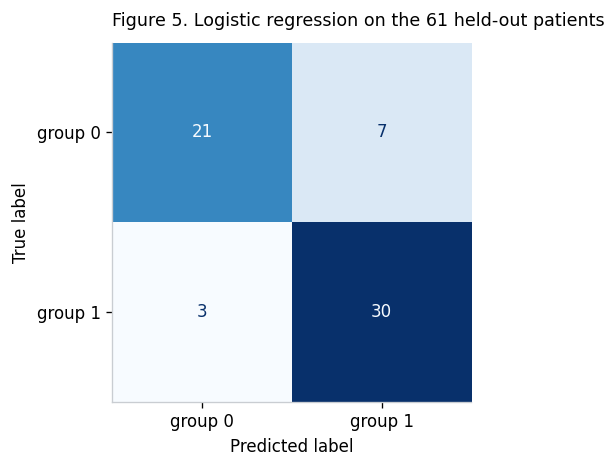

              precision    recall  f1-score   support

     group 0      0.875     0.750     0.808        28
     group 1      0.811     0.909     0.857        33

    accuracy                          0.836        61
   macro avg      0.843     0.830     0.832        61
weighted avg      0.840     0.836     0.834        61



In [18]:
# Logistic regression was selected on the cross-validated scores above (0.847 against 0.822
# and 0.776), which use training data only. The held-out set is used once, here, for reporting.
best_model = models["Logistic regression"]
y_pred = best_model.predict(X_test)

fig, ax = plt.subplots(figsize=(4.6, 4.0))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1],
    display_labels=["group 0", "group 1"], cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"Figure 5. Logistic regression on the {len(X_test)} held-out patients",
             fontsize=10.5, loc="left", pad=10)
ax.grid(False)
plt.tight_layout(); plt.show()

print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=["group 0", "group 1"], digits=3))

In [19]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
TP, FN = cm[0, 0], cm[0, 1]
FP, TN = cm[1, 0], cm[1, 1]

print("Treating group 0 as the class we are trying to detect:")
print()
print(f"  True positives  (correctly flagged):  {TP}")
print(f"  False negatives (missed):             {FN}")
print(f"  False positives (false alarm):        {FP}")
print(f"  True negatives  (correctly cleared):  {TN}")
print()
print(f"  Sensitivity (recall, group 0): {TP}/{TP+FN} = {TP/(TP+FN):.3f}")
print(f"  Specificity (recall, group 1): {TN}/{TN+FP} = {TN/(TN+FP):.3f}")
print(f"  PPV        (precision, grp 0): {TP}/{TP+FP} = {TP/(TP+FP):.3f}")
print(f"  NPV        (precision, grp 1): {TN}/{TN+FN} = {TN/(TN+FN):.3f}")

Treating group 0 as the class we are trying to detect:

  True positives  (correctly flagged):  21
  False negatives (missed):             7
  False positives (false alarm):        3
  True negatives  (correctly cleared):  30

  Sensitivity (recall, group 0): 21/28 = 0.750
  Specificity (recall, group 1): 30/33 = 0.909
  PPV        (precision, grp 0): 21/24 = 0.875
  NPV        (precision, grp 1): 30/37 = 0.811


**Which cell is which, and why we have to say so.** The four labels are not properties of the model. They
depend on which class you designate as the one you are trying to detect, and nothing in `sklearn` makes that
choice for you: `confusion_matrix` simply sorts by label value, and the binary metric functions default to
treating `1` as positive.

We designate **group 0** as the class to detect, because every clinical indicator in Figure 2 points to
group 0 being the group with disease. On that designation:

| Cell | Count | What it means for the clinic |
|---|---|---|
| True positive | 21 | Correctly flagged for further testing |
| False negative | 7 | **Missed.** Risk underestimated, may not be referred |
| False positive | 3 | False alarm. Costs an unnecessary follow-up test |
| True negative | 30 | Correctly cleared |

If the published label coding turns out to be right instead, every one of these four labels swaps, and the
model's problem becomes over-referral rather than under-referral. The counts do not move; only their names
do.

**Reading Figure 5.** Of 61 patients the model had never seen, it classified most correctly, but the errors
are not evenly split between the two groups. Recall for group 0 is **0.750** against **0.909** for group 1.
The model is noticeably better at identifying group 1 than group 0.

Whether that is the dangerous direction depends on the label question from Q2. **If group 0 is the disease
group**, which is what every clinical indicator in section 2.2 suggests, then the model misses one in four
patients who have the disease while catching nine in ten who do not. For a referral tool that is the wrong
way round, because a missed case is a patient whose risk is underestimated and who may not be sent for
further investigation, while a false alarm costs an unnecessary follow-up test.

Two things follow. First, a single accuracy figure would have hidden this completely, which is why the
confusion matrix is here. Second, the fix is not a better model. It is the decision threshold: we classify
at a predicted probability of 0.5, which is a software default with no clinical meaning. Lowering it catches
more of group 0 at the cost of more false alarms. **That trade is a clinical judgement, not a statistical
one**, and we flag it rather than making it ourselves.

### 4.3 A fuller set of metrics

Accuracy at a fixed threshold is one view. Precision and recall describe the two error types separately,
and **ROC AUC** describes how well a model *ranks* patients by risk regardless of where the threshold is
set. That distinction matters for us, because our conclusion in section 6 is about the threshold.

In [20]:
# Full metric comparison across the three models. Group 0 is treated as the class to detect.
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score

comparison = []
for name, model in models.items():
    y_hat  = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    p0, r0, f0, _ = precision_recall_fscore_support(y_test, y_hat, labels=[0], average=None)
    _, _, f_macro, _ = precision_recall_fscore_support(y_test, y_hat, average="macro")
    comparison.append({
        "model": name,
        "accuracy":          accuracy_score(y_test, y_hat),
        "precision (grp 0)": p0[0],
        "recall (grp 0)":    r0[0],
        "F1 (grp 0)":        f0[0],
        "F1 macro":          f_macro,
        "ROC AUC":           roc_auc_score(y_test, y_prob),
    })

comparison_df = pd.DataFrame(comparison).set_index("model").round(3)
comparison_df

,accuracy,precision (grp 0),recall (grp 0),F1 (grp 0),F1 macro,ROC AUC
model,,,,,,
Logistic regression,0.836,0.875,0.750,0.808,0.832,0.895
Decision tree (depth 4),0.721,0.739,0.607,0.667,0.714,0.744
Random forest (200 trees),0.754,0.783,0.643,0.706,0.747,0.894


**What this adds.** Logistic regression leads on all six measures, but the ROC AUC comparison deserves a
closer look than the others. At **0.895** against **0.894** for the random forest, those two are a tie; the
difference is a thousandth, far smaller than the fold variation we reported in section 4.1.

That is worth stating because ROC AUC and the other five metrics ask different questions. ROC AUC measures
how well a model **ranks** patients by risk across every possible threshold. The other five all depend on
where the 0.5 cut happens to fall. So the forest ranks patients essentially as well as logistic regression
does, yet classifies them noticeably worse (0.754 against 0.836). A model can rank well and still place the
cut badly, and that is what the forest is doing here.

This matters for our conclusion. If the problem were poor ranking, we would need a better model. Because
the ranking is sound and the classification is not, the lever is the threshold, which is what we recommend
in section 6.

**Recall for group 0 is the single metric that matters most for us**, because group 0 is the group whose
clinical profile points to disease. Logistic regression leads there as well at **0.750** against 0.643 for
the forest and 0.607 for the tree. Even so, missing one in four is not good enough for a screening tool
used on its own.

## 5. Interpret the model

### Q5. Explain feature contributions, sign/magnitude where possible


**Two different units on one chart, and we need to be precise about it.** The scaler in our pipeline is
applied to the numeric branch only, so the ten numeric columns are standardised and the seven one-hot
columns are not. The coefficients are therefore not all in the same unit:

- For a **numeric** variable (`ca`, `chol`, `thalach`, `oldpeak`, `age` and the binary ones), the
  coefficient is the change in log-odds for a **one standard deviation** increase. These are comparable to
  one another.
- For a **one-hot** column (`cp_*`, `restecg_*`, `thal_*`), it is the change in log-odds for **being in
  that category rather than the reference category**. One standard deviation of a 0/1 dummy is not a
  meaningful quantity, which is why we do not scale them.

The chart below ranks by magnitude, but a dummy coefficient and a numeric coefficient answer slightly
different questions. We say so rather than quietly comparing them.

In [21]:
# Standardised coefficients and odds ratios from the fitted logistic regression.
onehot = best_model.named_steps["prep"].named_transformers_["nom"].named_steps["onehot"]
feature_names = list(NUMERIC) + list(onehot.get_feature_names_out(NOMINAL))

lr = best_model.named_steps["clf"]
coefs = pd.DataFrame({"coefficient": lr.coef_[0],
                      "odds ratio":  np.exp(lr.coef_[0])}, index=feature_names)
coefs["abs"] = coefs["coefficient"].abs()
coefs = coefs.sort_values("abs", ascending=False).drop(columns="abs")
coefs.round(3)

,coefficient,odds ratio
cp_2.0,1.408,4.088
cp_3.0,1.241,3.459
thal_2.0,0.917,2.501
ca,-0.782,0.458
cp_1.0,0.718,2.050
thal_3.0,-0.678,0.507
sex,-0.534,0.586
chol,-0.507,0.602
restecg_1.0,0.498,1.645
exang,-0.469,0.625


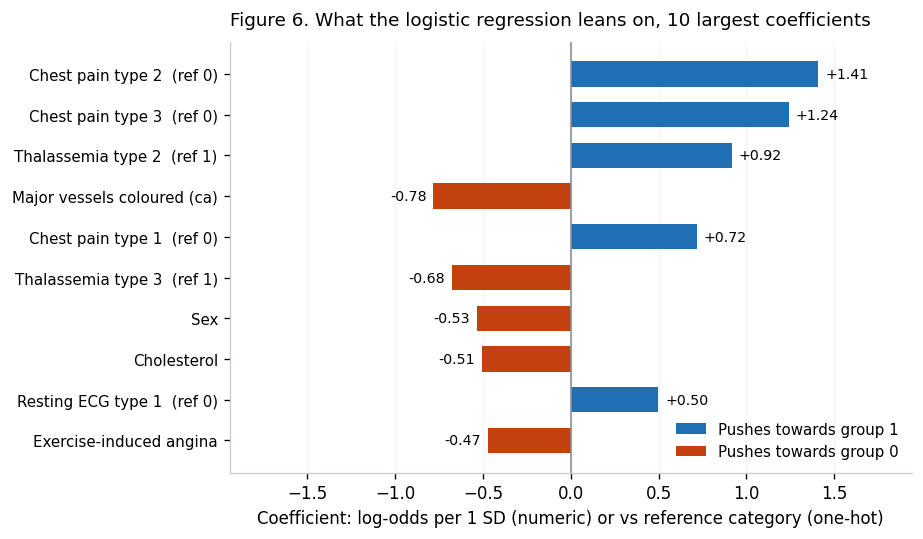

In [22]:
# Figure 6: the ten largest standardised coefficients, with direction.
PRETTY = {**LABELS,
          "cp_1.0": "Chest pain type 1  (ref 0)", "cp_2.0": "Chest pain type 2  (ref 0)",
          "cp_3.0": "Chest pain type 3  (ref 0)",
          "thal_2.0": "Thalassemia type 2  (ref 1)", "thal_3.0": "Thalassemia type 3  (ref 1)",
          "restecg_1.0": "Resting ECG type 1  (ref 0)", "restecg_2.0": "Resting ECG type 2  (ref 0)"}

top = coefs.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.8, 4.6))
ypos = np.arange(len(top))
ax.barh(ypos, top["coefficient"], height=0.62,
        color=[RUST if v < 0 else BLUE for v in top["coefficient"]])
ax.set_yticks(ypos); ax.set_yticklabels([PRETTY.get(i, i) for i in top.index], fontsize=9)
ax.axvline(0, color=GREY, lw=1)
for yy, v in zip(ypos, top["coefficient"]):
    ax.text(v + (0.04 if v > 0 else -0.04), yy, f"{v:+.2f}",
            va="center", ha="left" if v > 0 else "right", fontsize=8.5)
lim = float(top["coefficient"].abs().max()) * 1.38
ax.set_xlim(-lim, lim)
ax.set_xlabel("Coefficient: log-odds per 1 SD (numeric) or vs reference category (one-hot)")
ax.set_title("Figure 6. What the logistic regression leans on, 10 largest coefficients",
             fontsize=11, loc="left", pad=10)
ax.legend(handles=[Patch(facecolor=BLUE, label="Pushes towards group 1"),
                   Patch(facecolor=RUST, label="Pushes towards group 0")],
          loc="lower right", frameon=False, fontsize=9)
ax.grid(axis="x", alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

**Reading Figure 6.** Chest pain type dominates. All three non-reference chest pain categories carry
large positive coefficients, the largest being type 2 at **+1.41**, which means a patient in that category
has roughly four times the odds of being classified group 1 compared with the reference category, holding
everything else fixed. Affected vessel count (`ca`) which section 3 keeps as an ordinal number, is the strongest non-encoded contributor at **-0.78**,
and the thallium scan categories contribute in both directions.

**Direction.** Positive coefficients push a patient towards group 1, negative towards group 0. Given the
label uncertainty from Q2, we state the clinical reading conditionally: if group 0 is the disease group,
then a higher affected-vessel count, exercise-induced angina and higher cholesterol all push towards
disease, which is the direction a cardiologist would expect. If the published coding is right instead, every
one of those signs runs backwards and would need explaining. **The magnitudes and the ranking do not depend
on the label at all.** Only the clinical direction does.

In [23]:
# Why does age have a positive coefficient when its correlation is negative?
# Add predictors one at a time and watch the age coefficient move.
steps = [["age"], ["age", "thalach"], ["age", "thalach", "oldpeak"],
         ["age", "thalach", "oldpeak", "ca"]]

print("age coefficient as predictors are added:")
print()
for cols in steps:
    m = Pipeline([("prep", make_preprocessor(scale=True, numeric=cols, nominal=[])),
                  ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
    m.fit(X_train[cols], y_train)
    coef = dict(zip(cols, m.named_steps["clf"].coef_[0]))["age"]
    print(f"  {chr(39) + chr(39).join([]) if False else ' + '.join(cols):<34} {coef:+.3f}")

print()
print(f"  correlation, age with thalach: {heart['age'].corr(heart['thalach']):+.3f}")
print(f"  correlation, age with ca:      {heart['age'].corr(heart['ca']):+.3f}")

age coefficient as predictors are added:

  age                                -0.432
  age + thalach                      -0.132
  age + thalach + oldpeak            -0.114
  age + thalach + oldpeak + ca       +0.173

  correlation, age with thalach: -0.395
  correlation, age with ca:      +0.365


**A sign that reverses, and why.** Section 2 shows group 0 is the older group, and Figure 1 gives `age` a
correlation of -0.22, both pointing the same way. Yet `age` has a **positive** coefficient of +0.147, which
by the convention above points towards group 1.

The cell above traces it. Fitted alone, `age` has a coefficient of **-0.432**, matching the direction of
its correlation. Adding `thalach` shrinks that to **-0.132**, because maximum heart rate falls with age and
absorbs most of the signal. Adding `oldpeak` barely moves it, to -0.114.

The sign only **flips when `ca` enters**, to **+0.173**. Age and affected vessel count correlate at
**+0.365**: older patients tend to have more affected vessels. Once `ca` carries that part of the story,
the residual left for `age` runs the other way.

This is a worked example of why a coefficient cannot be read as though it were a correlation. It is
conditional on everything else in the model, and which variable it is conditional on can decide its sign.

**The most useful thing in Figure 6.** Cholesterol correlates with the outcome at only **-0.08**, near the
bottom of Figure 1, yet its standardised coefficient is **-0.51**, among the ten largest here. That is not a
contradiction. A correlation asks what a variable does **on its own**. A coefficient asks what it adds
**once every other variable is held constant**. Those are different questions, and cholesterol answers them
differently: it carries little signal in isolation but contributes real information alongside the others.

The reverse case is in the same figure. `ca` has the strongest correlation in the whole dataset, and
section 6.1 measures what removing it actually costs. Correlation tells you what a variable is worth alone;
only an ablation tells you what is lost when it goes.

**One honest caveat about `ca`.** The affected vessel count comes from a catheter procedure, and the original
diagnosis in this dataset was also made by catheter. So `ca` is partly a restatement of the label rather than
an independent predictor. That is one of the reasons the next section exists.

### 5.1 A second opinion: what the random forest ranks as important

The coefficients above come from one model. The random forest measures importance a different way, by how
much each feature reduces impurity across its 200 trees. Comparing the two is a check on whether the
ranking is a property of the data or an artefact of logistic regression.

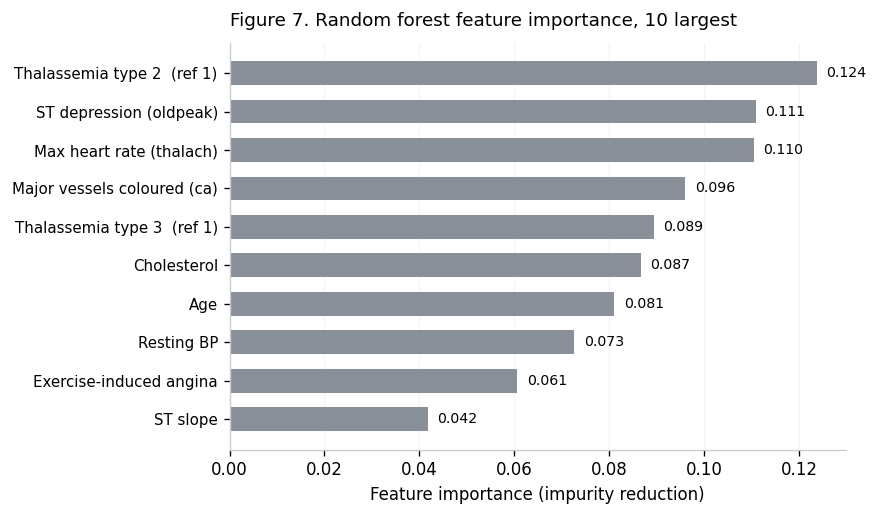

,0
thal_2.0,0.124
oldpeak,0.111
thalach,0.110
ca,0.096
thal_3.0,0.089
chol,0.087
age,0.081
trestbps,0.073
exang,0.061
slope,0.042


In [24]:
# Random forest feature importance, for comparison with the coefficients above.
rf = models["Random forest (200 trees)"]
rf_feat = (list(NUMERIC)
           + list(rf.named_steps["prep"].named_transformers_["nom"]
                    .named_steps["onehot"].get_feature_names_out(NOMINAL)))
importances = pd.Series(rf.named_steps["clf"].feature_importances_,
                        index=rf_feat).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7.4, 4.4))
top_imp = importances.head(10).iloc[::-1]
ax.barh(np.arange(len(top_imp)), top_imp.values, height=0.62, color=GREY)
ax.set_yticks(np.arange(len(top_imp)))
ax.set_yticklabels([PRETTY.get(i, i) for i in top_imp.index], fontsize=9)
for yy, v in zip(np.arange(len(top_imp)), top_imp.values):
    ax.text(v + 0.002, yy, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_xlabel("Feature importance (impurity reduction)")
ax.set_title("Figure 7. Random forest feature importance, 10 largest",
             fontsize=11, loc="left", pad=10)
ax.grid(axis="x", alpha=0.5); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

importances.round(3).head(10)

**Reading Figure 7. The two models disagree, and the disagreement is informative.** We expected broad
agreement and did not get it. Chest pain type dominates the logistic regression, yet no chest pain column
appears in the forest's top ten at all. Running the other way, `oldpeak`, `thalach` and `age` sit near the
top for the forest and well down the coefficient list.

Two things explain it. One-hot encoding **splits** chest pain across three columns, so its importance is
divided three ways while the regression gets a separate coefficient for each. And impurity-based importance
favours continuous variables, because they offer far more candidate split points than a 0/1 column. The two
measures agree only on `ca` and the thallium scan.

So neither ranking is "the" answer. They are two different questions, and the deeper difference is this.
**Feature importance has no sign.** It can say that `ca` is influential; it cannot say whether more
affected vessels raises or lowers the odds. Only the regression coefficients in Figure 6 give direction.

That is precisely why we chose logistic regression as our primary model. The second half of our question
asks which measurements carry the signal, and a defensible answer to that needs direction as well as
magnitude.

### 5.2 Why the predictors overlap

Section 6 removes the two expensive measurements and finds the cost is smaller than their correlation with
the outcome would suggest. The reason is that the predictors are correlated with **each other**, so when one
is removed the others still carry much of the same information. The matrix below shows that directly.

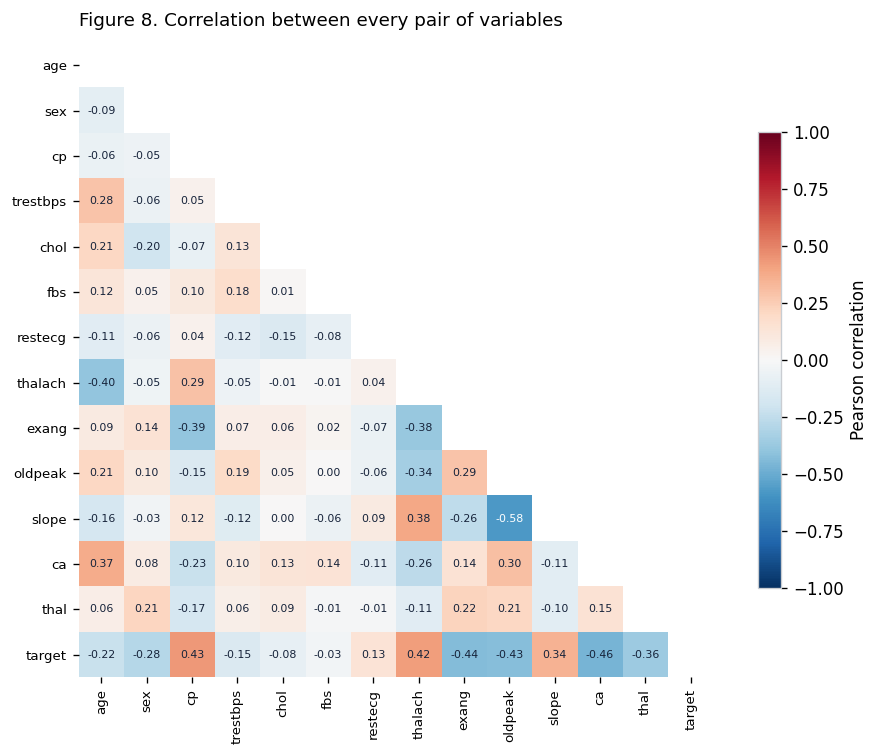

Strongest predictor-to-predictor relationships:
oldpeak  slope     -0.576
age      thalach   -0.395
cp       exang     -0.393
thalach  slope      0.385
         exang     -0.377


In [25]:
# Correlation between the predictors themselves, not just with the outcome.
corr_all = expl.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr_all, dtype=bool))

fig, ax = plt.subplots(figsize=(8.2, 6.4))
data = np.ma.masked_where(mask, corr_all.values)
im = ax.imshow(data, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_all))); ax.set_xticklabels(corr_all.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr_all))); ax.set_yticklabels(corr_all.index, fontsize=8)
for i in range(len(corr_all)):
    for j in range(len(corr_all)):
        if not mask[i, j]:
            v = corr_all.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.6,
                    color="white" if abs(v) > 0.55 else INK)
fig.colorbar(im, ax=ax, shrink=0.72, label="Pearson correlation")
ax.set_title("Figure 8. Correlation between every pair of variables",
             fontsize=11, loc="left", pad=10)
for sp in ax.spines.values():
    sp.set_visible(False)
plt.tight_layout(); plt.show()

pairs = (corr_all.where(~np.eye(len(corr_all), dtype=bool))
                 .unstack().dropna().drop_duplicates())
pairs = pairs[pairs.index.get_level_values(0) != "target"]
pairs = pairs[pairs.index.get_level_values(1) != "target"]
print("Strongest predictor-to-predictor relationships:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

**Reading Figure 8.** The bottom row is the outcome and repeats Figure 1. The rest of the matrix is the part
that matters here: how the predictors relate to **each other**.

`oldpeak` and `slope` are the strongest pair. Both describe the ST segment from the same exercise test, so
they largely restate one another. `age` and `thalach` are the next strongest, which is ordinary physiology:
maximum heart rate falls with age. That one is a genuine confound, because part of what looks like a heart
rate effect may be age acting through it.

This overlap is why the screening model in section 6 loses less than the raw correlations suggest it should.
Exercise-induced angina, ST depression and maximum heart rate all carry information about the same
underlying disease, so they partly cover for what is removed. Section 6.1 measures how far that cover
actually goes. **A correlation ranking
tells you what each variable is worth alone, it cannot tell you what is lost when one is taken away.**

## 6. Answering the question

Our question had two halves: can routine measurements predict heart-disease status well enough for
screening, and which measurements carry that signal. Section 5 answered the second half. This section
answers the first by refitting the model with the two expensive measurements removed.

In [26]:
# The screening model: same pipeline, without the two measurements that need
# a catheter (ca) or a nuclear scan (thal).
INVASIVE = ["ca", "thal"]
NUM_SCREEN = [c for c in NUMERIC if c not in INVASIVE]
NOM_SCREEN = [c for c in NOMINAL if c not in INVASIVE]

screening_model = Pipeline([
    ("prep", make_preprocessor(scale=True, numeric=NUM_SCREEN, nominal=NOM_SCREEN)),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

X_train_screen = X_train.drop(columns=INVASIVE)
X_test_screen  = X_test.drop(columns=INVASIVE)

full_cv   = cross_val_score(models["Logistic regression"], X_train, y_train, cv=5)
screen_cv = cross_val_score(screening_model, X_train_screen, y_train, cv=5)

print("Removed:", INVASIVE)
print(f"\nFull model,      5-fold CV: {full_cv.mean():.3f}  (fold SD {full_cv.std():.3f})")
print(f"Screening model, 5-fold CV: {screen_cv.mean():.3f}  (fold SD {screen_cv.std():.3f})")
print(f"\nCost of dropping the invasive tests: {(full_cv.mean()-screen_cv.mean())*100:.1f} percentage points")

signal_full   = full_cv.mean()   - baseline
signal_screen = screen_cv.mean() - baseline
print(f"\nAbove the {baseline:.3f} baseline:")
print(f"  full model adds      {signal_full*100:.1f} points of signal")
print(f"  screening model adds {signal_screen*100:.1f} points of signal")
print(f"  routine measurements retain {signal_screen/signal_full*100:.1f}% of the predictive signal")

screening_model.fit(X_train_screen, y_train)
print(f"\nScreening model on the held-out patients: {screening_model.score(X_test_screen, y_test):.3f}")

Removed: ['ca', 'thal']

Full model,      5-fold CV: 0.847  (fold SD 0.050)
Screening model, 5-fold CV: 0.776  (fold SD 0.062)

Cost of dropping the invasive tests: 7.0 percentage points

Above the 0.543 baseline:
  full model adds      30.4 points of signal
  screening model adds 23.3 points of signal
  routine measurements retain 76.8% of the predictive signal

Screening model on the held-out patients: 0.787


### 6.1 Which of the two expensive tests actually carried the weight

The comparison above removes `ca` and `thal` together, so it cannot tell us which one mattered. Before
drawing any conclusion about either, we remove them one at a time.

In [27]:
# Remove the invasive measurements one at a time to separate their contributions.
ablations = {"nothing removed": [], "ca only": ["ca"], "thal only": ["thal"], "ca and thal": INVASIVE}

rows = []
for label, drop in ablations.items():
    num = [c for c in NUMERIC if c not in drop]
    nom = [c for c in NOMINAL if c not in drop]
    pipe = Pipeline([("prep", make_preprocessor(scale=True, numeric=num, nominal=nom)),
                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
    cv = cross_val_score(pipe, X_train.drop(columns=drop), y_train, cv=5)
    pipe.fit(X_train.drop(columns=drop), y_train)
    rows.append({"removed":   label,
                 "5-fold CV": cv.mean(),
                 "held-out":  pipe.score(X_test.drop(columns=drop), y_test)})

pd.DataFrame(rows).set_index("removed").round(3)

,5-fold CV,held-out
removed,,
nothing removed,0.847,0.836
ca only,0.817,0.738
thal only,0.805,0.836
ca and thal,0.776,0.787


**This corrected an assumption we had made.** Our first reading of the screening result was that `ca` could
be dropped cheaply, because the other measurements overlap with it. The one-at-a-time test does not support
that.

Removing `ca` alone costs 3 points of cross-validated accuracy and nearly 10 points on the held-out
patients. Removing `thal` alone costs more in cross-validation but nothing at all on the held-out set. The
two are not interchangeable, and the combined drop is not attributable to either one on its own.

The honest statement is narrower than the one we started with: the routine measurements retain most of the
signal when both invasive tests are removed together**, which is the comparison a clinic actually faces.
They are deciding whether to order any invasive workup, not which one. But `ca` is doing real work, and we
would have reported the opposite had we not run this.

### Q6. Directly Answers the Question, Evaluates the Results, and Identifies Next Steps

Overall, we achieved most of our objectives, although there are a few important limitations to consider.

Removing the two measurements that require a catheter or a nuclear scan reduced cross-validated accuracy by **7.1 percentage points**, from **0.847 to 0.776**. Compared with the baseline accuracy of 0.543, the reduced model preserves approximately **77% of the predictive improvement** achieved by the full model. This suggests that a clinic equipped with an ECG, a treadmill, and patient history can generate a useful prediction without immediately requiring invasive testing.

**Did we achieve our desired outcome?** Partially, and each objective needs to be evaluated separately.

- **A model that performs substantially better than the baseline using routine measurements:** Yes. The screening model achieved a cross-validated accuracy of 0.776, compared with the baseline of 0.543, and an accuracy of 0.787 on the test set.
- **A clear ranking of the measurements and their relationship with the outcome:** Yes. Section 5 presents the relevant findings, although interpreting the direction of these relationships depends on confirming how the outcome labels were assigned.
- **A model reliable enough for clinical decisions:** Not yet. As discussed in Section 4.2, the model identifies one group more accurately than the other. At the default classification threshold, it misses approximately one-quarter of the patients in the group associated with the disease, which is a significant limitation.

**Overall conclusion**

Our results indicate that routine clinical measurements contain useful information for identifying potential heart-disease risk. However, the model should assist healthcare professionals in deciding whether further diagnostic testing is needed rather than replace established diagnostic procedures. Although the reduced model performs less accurately than the full model, this trade-off may be acceptable for an initial screening tool, provided its limitations are considered. The purpose of screening is to help identify patients who may need additional investigation, not to provide a definitive diagnosis.

**An unexpected finding**

The `ca` variable has the strongest correlation with the outcome in the dataset, at -0.46, yet removing it had very little effect on model performance. One possible explanation is that several predictors contain overlapping information. For example, exercise-induced angina, ST depression, and maximum heart rate may capture related aspects of a patient's condition. This finding highlights an important distinction: **a variable with a strong correlation is not necessarily the most important variable for prediction.**

**Recommended next steps, in order of priority**

1. **Verify the outcome labels.** Re-examine the original UCI `processed.cleveland.data` file, where the diagnosis variable contains values from 0 to 4 before being converted into a binary outcome. Confirming how these values were grouped is essential because an incorrect mapping could reverse the interpretation of the results. Until this is resolved, conclusions about the direction of the relationships between predictors and the outcome should be treated cautiously.

2. **Select a suitable classification threshold.** Rather than automatically using the default threshold of 0.5, evaluate how recall and precision change at different thresholds. The ROC AUC results in Section 4.3 suggest that the model can distinguish between patients reasonably well, but the classification threshold may not provide the best balance between missed cases and false alarms. Comparing `class_weight="balanced"` with alternative thresholds would help determine whether the model can identify more disease cases.

3. **Improve model tuning.** The current models use `max_depth=4` for the decision tree and `n_estimators=200` for the random forest without a systematic search for better settings. A grid search combined with nested cross-validation would help identify suitable hyperparameters while providing a more reliable estimate of model performance.

4. **Evaluate a more basic screening model.** The current model still includes exercise stress-test measurements, which may be available in a cardiology clinic but not in a general practitioner's office. Removing `thalach`, `exang`, `oldpeak`, and `slope` would allow us to assess how well a model performs using only patient history and measurements collected at rest.

In summary, the reduced model shows promising potential for preliminary heart-disease screening. However, validating the outcome labels, addressing differences in recall, and evaluating simpler predictors are important steps before considering its use in clinical practice.

---
### Limitations, in one place

| Limitation | Effect on what we can claim |
|---|---|
| Outcome label direction is contested | Signs in section 5 and the reading of Figure 5 are conditional. Magnitudes are not affected |
| Patients were already referred for angiography | Performance on a general primary-care population would be worse. Our numbers are an upper bound |
| `ca` derives from the same procedure as the diagnosis | It is partly circular as a predictor. The screening model in section 6 exists partly to test around this |
| One clinic, 1988, mostly male, 302 patients | Does not generalise to current practice, to women, or to other populations without retraining |
| No smoking, diet, family history or medication | Known major risk factors are simply absent |
| Hyperparameters not tuned | Results are for sensible defaults, not optimised models |